# Branch D — Level 2 integrated transition profiles

This notebook implements the second level of the agreed dimension-first strategy.

**Analysis population:** respondents whose validated final active branch is D in the new survey structure.  
**Inputs:** the five 0–100 Level 1 dimension scores, not the original 20–30 variables.  
**Primary method:** K-means on equally standardized dimension scores.  
**Candidate profile counts:** 3–5. Values 2 and 6 are shown only as boundary diagnostics.  
**Robustness checks:** respondent-resampling stability, K-medoids agreement, Ward-clustering agreement, and leave-one-dimension-out sensitivity.

The notebook does not interpret clusters as naturally occurring or causal groups. They are empirical summaries whose usefulness depends on separation, stability, robustness, and substantive review.

## Decision rules

1. Every respondent must have all five dimension scores; no Level 2 imputation is performed.
2. Each dimension is z-standardized so that the five dimensions have equal scale influence.
3. A substantive candidate must be between 3 and 5 profiles and contain at least 15 respondents in every profile.
4. Among eligible candidates, prefer solutions with bootstrap stability of at least 0.60. Rank the remaining solutions equally on silhouette, Calinski–Harabasz, Davies–Bouldin, bootstrap stability, and K-medoids agreement.
5. Profile numbers are reordered from lower to higher overall standardized position for reproducibility; they do not imply a value judgement or a developmental sequence.

Thresholds in the final quality panel are diagnostic guides, not universal statistical laws.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    pairwise_distances,
    silhouette_samples,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

ROOT = Path.cwd()
SCORE_PATH = ROOT / "outputs/branch_d_dimensions/branch_d_dimension_scores.csv"
DESCRIPTIVE_PATH = ROOT / "outputs/nysc_survey_branch_D_analysis_ready.csv"
ROUTING_PATH = ROOT / "outputs/nysc_survey_cleaned_values.csv"
OUT = ROOT / "outputs/branch_d_integrated_profiles"
OUT.mkdir(parents=True, exist_ok=True)

DIMENSIONS = [
    "economic_resources",
    "human_capital_trajectory",
    "career_transition_readiness",
    "social_capital_belonging",
    "agency_study_engagement",
]
FRIENDLY = {
    "economic_resources": "economic resources",
    "human_capital_trajectory": "human-capital trajectory",
    "career_transition_readiness": "career-transition readiness",
    "social_capital_belonging": "social capital and belonging",
    "agency_study_engagement": "agency and study engagement",
}
RANDOM_STATE = 20260823
MIN_PROFILE_SIZE = 15
BOOTSTRAP_REPETITIONS = 100

print("Level 1 score source:", SCORE_PATH)
print("Output directory:", OUT)

Level 1 score source: /Users/vimashafernando/Desktop/ClusterRP/outputs/branch_d_dimensions/branch_d_dimension_scores.csv
Output directory: /Users/vimashafernando/Desktop/ClusterRP/outputs/branch_d_integrated_profiles


## 1. Load and validate the Level 1 score matrix

The cohort identifiers and branch fields are checked again here. This protects Level 2 from accidentally using an entry branch, an earlier mid-survey branch, or records outside the strict final-active-Branch-D cohort.

In [2]:
scores = pd.read_csv(SCORE_PATH)
routing = pd.read_csv(
    ROUTING_PATH,
    usecols=["respondent_id", "branch", "branch_routing_source"],
)
route_check = scores[["respondent_id"]].merge(
    routing, on="respondent_id", how="left", validate="one_to_one"
)

validation = {
    "records": int(len(scores)),
    "unique_respondents": int(scores["respondent_id"].nunique()),
    "duplicate_respondent_ids": int(scores["respondent_id"].duplicated().sum()),
    "non_D_final_branch_rows": int(scores["branch"].ne("D").sum()),
    "missing_routing_audit_rows": int(route_check["branch"].isna().sum()),
    "routing_audit_non_D_rows": int(route_check["branch"].ne("D").sum()),
    "wrong_routing_source_rows": int(route_check["branch_routing_source"].ne("translated_final_active_branch").sum()),
    "missing_dimension_values": int(scores[DIMENSIONS].isna().sum().sum()),
    "non_finite_dimension_values": int((~np.isfinite(scores[DIMENSIONS].to_numpy(float))).sum()),
}

assert validation["records"] > 0, "The Level 1 score file is empty."
assert validation["duplicate_respondent_ids"] == 0, "Respondent IDs must be unique."
assert validation["non_D_final_branch_rows"] == 0, "A non-D record entered the Level 2 cohort."
assert validation["missing_routing_audit_rows"] == 0, "A Level 2 respondent is missing from the cleaned routing audit."
assert validation["routing_audit_non_D_rows"] == 0, "The routing audit does not confirm final Branch D."
assert validation["wrong_routing_source_rows"] == 0, "A record was not routed from translated final active branch."
assert validation["missing_dimension_values"] == 0, "Level 2 requires complete five-dimension scores."
assert validation["non_finite_dimension_values"] == 0, "Dimension scores must be finite."

display(pd.Series(validation, name="value").to_frame())
display(scores[DIMENSIONS].describe().T.round(3))

,value
records,191
unique_respondents,191
duplicate_respondent_ids,0
non_D_final_branch_rows,0
missing_routing_audit_rows,0
routing_audit_non_D_rows,0
wrong_routing_source_rows,0
missing_dimension_values,0
non_finite_dimension_values,0


,count,mean,std,min,25%,50%,75%,max
economic_resources,191.0,75.857,12.773,26.000,70.000,78.000,85.000,100.0
human_capital_trajectory,191.0,67.568,19.243,0.000,52.778,58.333,88.889,100.0
career_transition_readiness,191.0,81.492,18.932,0.000,75.000,80.000,100.000,100.0
social_capital_belonging,191.0,60.442,20.694,11.111,44.444,66.667,77.778,100.0
agency_study_engagement,191.0,72.324,20.291,8.333,58.333,77.778,88.889,100.0


## 2. Standardize the five equally weighted dimensions

Although all scores are on a 0–100 scale, their observed variances differ. Z-standardization prevents a more variable dimension from dominating Euclidean distance. PCA is **not** used to create the clusters; it is used later only for a two-dimensional plot.

In [3]:
X_raw = scores[DIMENSIONS].to_numpy(float)
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

standardization_audit = pd.DataFrame({
    "dimension": DIMENSIONS,
    "raw_mean": scaler.mean_,
    "raw_sd_population": scaler.scale_,
    "standardized_mean": X.mean(axis=0),
    "standardized_sd_population": X.std(axis=0),
})
display(standardization_audit.round(4))

,dimension,raw_mean,raw_sd_population,standardized_mean,standardized_sd_population
0,economic_resources,75.8572,12.7392,-0.0,1.0
1,human_capital_trajectory,67.5684,19.1923,0.0,1.0
2,career_transition_readiness,81.4921,18.8823,0.0,1.0
3,social_capital_belonging,60.4421,20.6397,0.0,1.0
4,agency_study_engagement,72.3240,20.2382,0.0,1.0


## 3. Compare candidate numbers of profiles

Bootstrap stability repeatedly resamples respondents, refits K-means, predicts membership for the original cohort, and compares that membership with the full-sample solution using the adjusted Rand index (ARI). K-medoids and Ward clustering provide algorithmic sensitivity checks.

In [4]:
def fit_kmedoids_alternate(X, k, n_init=50, max_iter=200, random_state=RANDOM_STATE):
    """Multiple-start Euclidean k-medoids using assignment/update alternation."""
    rng = np.random.default_rng(random_state)
    distances = pairwise_distances(X, metric="euclidean")
    n = len(X)
    best = None

    for _ in range(n_init):
        medoids = np.sort(rng.choice(n, size=k, replace=False))
        for _ in range(max_iter):
            labels = np.argmin(distances[:, medoids], axis=1)
            new_medoids = medoids.copy()
            for cluster in range(k):
                members = np.flatnonzero(labels == cluster)
                if len(members) == 0:
                    nearest = distances[:, medoids].min(axis=1)
                    candidates = np.setdiff1d(np.argsort(nearest)[::-1], new_medoids)
                    new_medoids[cluster] = candidates[0]
                else:
                    within = distances[np.ix_(members, members)]
                    new_medoids[cluster] = members[np.argmin(within.sum(axis=1))]
            if np.array_equal(new_medoids, medoids):
                break
            medoids = new_medoids

        labels = np.argmin(distances[:, medoids], axis=1)
        loss = float(distances[np.arange(n), medoids[labels]].sum())
        if best is None or loss < best[0]:
            best = (loss, medoids.copy(), labels.copy())

    return {"loss": best[0], "medoid_indices": best[1], "labels": best[2]}


def bootstrap_kmeans_stability(X, k, reference_labels, repetitions=100, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state + k)
    aris = []
    n = len(X)
    for b in range(repetitions):
        idx = rng.choice(n, size=n, replace=True)
        model = KMeans(n_clusters=k, n_init=30, random_state=random_state + 1000 * k + b)
        model.fit(X[idx])
        aris.append(adjusted_rand_score(reference_labels, model.predict(X)))
    return np.asarray(aris)


candidate_rows = []
stability_rows = []
candidate_models = {}

for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=200, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    candidate_models[k] = model
    stability = bootstrap_kmeans_stability(X, k, labels, BOOTSTRAP_REPETITIONS)
    medoid = fit_kmedoids_alternate(X, k, n_init=100, random_state=RANDOM_STATE + k)
    ward_labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    sizes = np.bincount(labels, minlength=k)

    candidate_rows.append({
        "k": k,
        "substantive_candidate": 3 <= k <= 5,
        "silhouette": silhouette_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "bootstrap_ari_mean": stability.mean(),
        "bootstrap_ari_p10": np.quantile(stability, 0.10),
        "kmedoids_ari": adjusted_rand_score(labels, medoid["labels"]),
        "ward_ari": adjusted_rand_score(labels, ward_labels),
        "minimum_profile_size": int(sizes.min()),
        "maximum_profile_size": int(sizes.max()),
    })
    stability_rows.extend({"k": k, "repetition": b + 1, "ari": value} for b, value in enumerate(stability))

candidate_metrics = pd.DataFrame(candidate_rows)
bootstrap_stability = pd.DataFrame(stability_rows)

eligible_mask = (
    candidate_metrics["substantive_candidate"]
    & candidate_metrics["minimum_profile_size"].ge(MIN_PROFILE_SIZE)
)
eligible = candidate_metrics.loc[eligible_mask].copy()
if eligible.empty:
    raise RuntimeError("No 3–5 profile candidate meets the minimum profile-size rule.")

stable = eligible.loc[eligible["bootstrap_ari_mean"].ge(0.60)].copy()
ranking_pool = stable if not stable.empty else eligible
ranking_pool["rank_silhouette"] = ranking_pool["silhouette"].rank(ascending=False, method="min")
ranking_pool["rank_calinski_harabasz"] = ranking_pool["calinski_harabasz"].rank(ascending=False, method="min")
ranking_pool["rank_davies_bouldin"] = ranking_pool["davies_bouldin"].rank(ascending=True, method="min")
ranking_pool["rank_bootstrap_stability"] = ranking_pool["bootstrap_ari_mean"].rank(ascending=False, method="min")
ranking_pool["rank_kmedoids_agreement"] = ranking_pool["kmedoids_ari"].rank(ascending=False, method="min")
ranking_pool["mean_rank"] = ranking_pool[[
    "rank_silhouette", "rank_calinski_harabasz", "rank_davies_bouldin",
    "rank_bootstrap_stability", "rank_kmedoids_agreement",
]].mean(axis=1)

best_rank = ranking_pool["mean_rank"].min()
selected_k = int(ranking_pool.loc[ranking_pool["mean_rank"].eq(best_rank), "k"].min())
candidate_metrics = candidate_metrics.merge(
    ranking_pool[["k", "mean_rank"]], on="k", how="left"
)
candidate_metrics["selected"] = candidate_metrics["k"].eq(selected_k)

selection_reason = (
    f"Selected k={selected_k} from the eligible 3–5 profile candidates using the lowest equal-weight "
    "mean rank across separation, compactness, bootstrap stability, and K-medoids agreement."
)
print(selection_reason)
display(candidate_metrics.round(4))

Selected k=3 from the eligible 3–5 profile candidates using the lowest equal-weight mean rank across separation, compactness, bootstrap stability, and K-medoids agreement.


,k,substantive_candidate,silhouette,calinski_harabasz,davies_bouldin,bootstrap_ari_mean,bootstrap_ari_p10,kmedoids_ari,ward_ari,minimum_profile_size,maximum_profile_size,mean_rank,selected
0,2,False,0.2007,41.6358,1.9291,0.3305,-0.0071,0.8378,-0.0040,73,118,NaN,False
1,3,True,0.1861,42.6315,1.6474,0.5742,0.2987,0.5050,0.4077,52,87,1.8,True
2,4,True,0.1868,40.3562,1.5677,0.5137,0.3015,0.2346,0.3333,27,72,2.2,False
3,5,True,0.1879,38.8755,1.4849,0.5002,0.3409,0.4716,0.3156,24,54,2.0,False
4,6,False,0.1855,38.5719,1.3507,0.5626,0.3863,0.3784,0.3972,18,48,NaN,False


## 4. Fit, reorder, and label the selected solution

K-means profile IDs are relabelled by ascending mean standardized position. The descriptive labels identify the largest centroid deviations, not fixed theoretical categories. Always use the full centroid table when interpreting a profile.

In [5]:
final_model = candidate_models[selected_k]
old_labels = final_model.labels_.copy()

# Stable presentation order: lower to higher mean standardized centroid.
old_order = np.argsort(final_model.cluster_centers_.mean(axis=1))
old_to_profile = {int(old): int(new + 1) for new, old in enumerate(old_order)}
profile_id = np.array([old_to_profile[int(label)] for label in old_labels])

# Match K-medoids labels to K-means profile IDs by maximum overlap.
medoid_solution = fit_kmedoids_alternate(X, selected_k, n_init=100, random_state=RANDOM_STATE + selected_k)
medoid_labels = medoid_solution["labels"]
overlap = np.zeros((selected_k, selected_k), dtype=int)
for i in range(selected_k):
    for j in range(selected_k):
        overlap[i, j] = np.sum((profile_id == i + 1) & (medoid_labels == j))
rows, cols = linear_sum_assignment(-overlap)
medoid_to_profile = {int(col): int(row + 1) for row, col in zip(rows, cols)}
medoid_profile_id = np.array([medoid_to_profile[int(label)] for label in medoid_labels])

z_scores = pd.DataFrame(X, columns=DIMENSIONS)
z_scores["profile_id"] = profile_id
profile_z = z_scores.groupby("profile_id")[DIMENSIONS].mean()

def make_profile_name(profile_number, row):
    ordered = row.abs().sort_values(ascending=False).index.tolist()
    phrases = []
    for dimension in ordered[:2]:
        value = row[dimension]
        if abs(value) >= 0.35:
            direction = "higher" if value > 0 else "lower"
            phrases.append(f"{direction} {FRIENDLY[dimension]}")
    description = " and ".join(phrases) if phrases else "near-average across dimensions"
    return f"Profile {profile_number}: {description}"

profile_names = {
    int(pid): make_profile_name(int(pid), profile_z.loc[pid])
    for pid in profile_z.index
}

assigned_centres = np.vstack([
    final_model.cluster_centers_[old_labels[i]] for i in range(len(X))
])
distance_to_centroid = np.linalg.norm(X - assigned_centres, axis=1)
individual_silhouette = silhouette_samples(X, old_labels)

assignments = scores[["respondent_id", "entry_branch", "branch"] + DIMENSIONS].copy()
assignments["profile_id"] = profile_id
assignments["profile_label"] = assignments["profile_id"].map(profile_names)
assignments["distance_to_centroid_z"] = distance_to_centroid
assignments["individual_silhouette"] = individual_silhouette
assignments["low_confidence_membership"] = individual_silhouette < 0.10
assignments["kmedoids_profile_id"] = medoid_profile_id
assignments["kmedoids_agrees"] = assignments["profile_id"].eq(assignments["kmedoids_profile_id"])

profile_sizes = (
    assignments.groupby(["profile_id", "profile_label"], as_index=False)
    .agg(records=("respondent_id", "size"),
         low_confidence_records=("low_confidence_membership", "sum"),
         mean_individual_silhouette=("individual_silhouette", "mean"))
)
profile_sizes["percent"] = 100 * profile_sizes["records"] / len(assignments)

display(profile_sizes.round(3))
display(profile_z.rename(columns=FRIENDLY).round(3))

,profile_id,profile_label,records,low_confidence_records,mean_individual_silhouette,percent
0,1,Profile 1: lower agency and study engagement a...,52,27,0.102,27.225
1,2,Profile 2: lower human-capital trajectory and ...,87,18,0.184,45.550
2,3,Profile 3: higher human-capital trajectory and...,52,2,0.274,27.225


,economic resources,human-capital trajectory,career-transition readiness,social capital and belonging,agency and study engagement
profile_id,,,,,
1,-0.004,-0.142,-0.929,-0.485,-1.027
2,-0.391,-0.604,0.308,0.339,0.426
3,0.657,1.153,0.415,-0.081,0.314


## 5. Profile the integrated solution

The 0–100 means preserve the meaning of the Level 1 scores. Standardized centroid deviations show what most distinguishes each profile from this Branch D cohort. Positive values mean above the Branch D average; negative values mean below it.

In [6]:
profile_means = assignments.groupby(["profile_id", "profile_label"])[DIMENSIONS].mean()
profile_medians = assignments.groupby(["profile_id", "profile_label"])[DIMENSIONS].median()
profile_sds = assignments.groupby(["profile_id", "profile_label"])[DIMENSIONS].std()

profile_z_export = profile_z.copy()
profile_z_export.insert(0, "profile_label", [profile_names[int(i)] for i in profile_z_export.index])

distinguishing_rows = []
for pid, row in profile_z.iterrows():
    order = row.abs().sort_values(ascending=False)
    for rank, dimension in enumerate(order.index, start=1):
        distinguishing_rows.append({
            "profile_id": int(pid),
            "profile_label": profile_names[int(pid)],
            "rank_by_absolute_deviation": rank,
            "dimension": dimension,
            "dimension_label": FRIENDLY[dimension],
            "centroid_z": row[dimension],
            "direction_vs_branch_D_mean": "above" if row[dimension] > 0 else "below",
        })
distinguishing = pd.DataFrame(distinguishing_rows)

print("Mean dimension scores (0–100):")
display(profile_means.round(2))
print("Largest standardized deviations:")
display(distinguishing.query("rank_by_absolute_deviation <= 2").round(3))

Mean dimension scores (0–100):


,,economic_resources,human_capital_trajectory,career_transition_readiness,social_capital_belonging,agency_study_engagement
profile_id,profile_label,,,,,
1,Profile 1: lower agency and study engagement and lower career-transition readiness,75.81,64.85,63.94,50.43,51.55
2,Profile 2: lower human-capital trajectory and higher agency and study engagement,70.88,55.97,87.30,67.43,80.94
3,Profile 3: higher human-capital trajectory and higher economic resources,84.23,89.69,89.33,58.76,78.69


Largest standardized deviations:


,profile_id,profile_label,rank_by_absolute_deviation,dimension,dimension_label,centroid_z,direction_vs_branch_D_mean
0,1,Profile 1: lower agency and study engagement a...,1,agency_study_engagement,agency and study engagement,-1.027,below
1,1,Profile 1: lower agency and study engagement a...,2,career_transition_readiness,career-transition readiness,-0.929,below
5,2,Profile 2: lower human-capital trajectory and ...,1,human_capital_trajectory,human-capital trajectory,-0.604,below
6,2,Profile 2: lower human-capital trajectory and ...,2,agency_study_engagement,agency and study engagement,0.426,above
10,3,Profile 3: higher human-capital trajectory and...,1,human_capital_trajectory,human-capital trajectory,1.153,above
11,3,Profile 3: higher human-capital trajectory and...,2,economic_resources,economic resources,0.657,above


## 6. Descriptive composition

These variables were not supplied directly to Level 2 K-means. Their distributions help describe the profiles. Differences remain descriptive and should not be treated as causal explanations or external validation.

In [7]:
descriptive = pd.read_csv(DESCRIPTIVE_PATH)
descriptive_columns = [
    c for c in [
        "age_group", "gender", "district", "area_type", "marital_status",
        "household_income", "highest_edu_completed", "worked_while_studying",
    ] if c in descriptive.columns
]

profile_descriptive = assignments[["respondent_id", "profile_id", "profile_label"]].merge(
    descriptive[["respondent_id"] + descriptive_columns], on="respondent_id", how="left", validate="one_to_one"
)
composition_rows = []
for variable in descriptive_columns:
    temp = (
        profile_descriptive.groupby(["profile_id", "profile_label", variable], dropna=False)
        .size().rename("records").reset_index()
    )
    temp["within_profile_percent"] = 100 * temp["records"] / temp.groupby("profile_id")["records"].transform("sum")
    temp = temp.rename(columns={variable: "category"})
    temp.insert(2, "variable", variable)
    composition_rows.append(temp)
profile_composition = pd.concat(composition_rows, ignore_index=True)

display(
    profile_composition.loc[profile_composition["variable"].isin(["gender", "area_type", "age_group"])]
    .sort_values(["variable", "profile_id", "within_profile_percent"], ascending=[True, True, False])
    .round(2)
)

,profile_id,profile_label,variable,category,records,within_profile_percent
1,1,Profile 1: lower agency and study engagement a...,age_group,22 – 25 years,33,63.46
0,1,Profile 1: lower agency and study engagement a...,age_group,18 – 21 years,14,26.92
2,1,Profile 1: lower agency and study engagement a...,age_group,26 – 29 years,5,9.62
5,2,Profile 2: lower human-capital trajectory and ...,age_group,22 – 25 years,66,75.86
4,2,Profile 2: lower human-capital trajectory and ...,age_group,18 – 21 years,13,14.94
6,2,Profile 2: lower human-capital trajectory and ...,age_group,26 – 29 years,6,6.90
3,2,Profile 2: lower human-capital trajectory and ...,age_group,15 – 17 years,1,1.15
7,2,Profile 2: lower human-capital trajectory and ...,age_group,30 – 35 years,1,1.15
10,3,Profile 3: higher human-capital trajectory and...,age_group,22 – 25 years,40,76.92
9,3,Profile 3: higher human-capital trajectory and...,age_group,18 – 21 years,7,13.46


## 7. Robustness and sensitivity

The leave-one-dimension-out check asks whether the same solution broadly survives when each dimension is removed in turn. Low agreement for one omitted dimension means that dimension is influential, not necessarily that it is wrong.

In [8]:
ward_labels = AgglomerativeClustering(n_clusters=selected_k, linkage="ward").fit_predict(X)
algorithm_comparison = pd.DataFrame([
    {
        "comparison": "K-means vs K-medoids",
        "adjusted_rand_index": adjusted_rand_score(profile_id, medoid_profile_id),
        "interpretation": "sensitivity to centroid versus observed-medoid representation",
    },
    {
        "comparison": "K-means vs Ward",
        "adjusted_rand_index": adjusted_rand_score(profile_id, ward_labels),
        "interpretation": "sensitivity to partitioning versus hierarchical clustering",
    },
])

leave_one_out_rows = []
for omitted in DIMENSIONS:
    kept = [d for d in DIMENSIONS if d != omitted]
    X_reduced = StandardScaler().fit_transform(scores[kept])
    reduced_labels = KMeans(
        n_clusters=selected_k, n_init=200, random_state=RANDOM_STATE
    ).fit_predict(X_reduced)
    leave_one_out_rows.append({
        "omitted_dimension": omitted,
        "adjusted_rand_index_vs_full_solution": adjusted_rand_score(profile_id, reduced_labels),
    })
leave_one_out = pd.DataFrame(leave_one_out_rows)

selected_metrics = candidate_metrics.loc[candidate_metrics["k"].eq(selected_k)].iloc[0]
quality_checks = pd.DataFrame([
    {"check": "overall silhouette >= 0.25", "value": selected_metrics["silhouette"], "passed": selected_metrics["silhouette"] >= 0.25},
    {"check": "bootstrap mean ARI >= 0.75", "value": selected_metrics["bootstrap_ari_mean"], "passed": selected_metrics["bootstrap_ari_mean"] >= 0.75},
    {"check": f"minimum profile size >= {MIN_PROFILE_SIZE}", "value": selected_metrics["minimum_profile_size"], "passed": selected_metrics["minimum_profile_size"] >= MIN_PROFILE_SIZE},
    {"check": "K-medoids agreement ARI >= 0.60", "value": algorithm_comparison.iloc[0]["adjusted_rand_index"], "passed": algorithm_comparison.iloc[0]["adjusted_rand_index"] >= 0.60},
    {"check": "median leave-one-dimension-out ARI >= 0.50", "value": leave_one_out["adjusted_rand_index_vs_full_solution"].median(), "passed": leave_one_out["adjusted_rand_index_vs_full_solution"].median() >= 0.50},
])
interpretation_status = (
    "Proceed to substantive profile interpretation"
    if quality_checks["passed"].all()
    else "Provisional solution — interpret with the failed diagnostics clearly reported"
)

display(algorithm_comparison.round(3))
display(leave_one_out.round(3))
display(quality_checks.round(3))
print("Status:", interpretation_status)

,comparison,adjusted_rand_index,interpretation
0,K-means vs K-medoids,0.505,sensitivity to centroid versus observed-medoid...
1,K-means vs Ward,0.408,sensitivity to partitioning versus hierarchica...


,omitted_dimension,adjusted_rand_index_vs_full_solution
0,economic_resources,0.790
1,human_capital_trajectory,0.298
2,career_transition_readiness,0.654
3,social_capital_belonging,0.801
4,agency_study_engagement,0.618


,check,value,passed
0,overall silhouette >= 0.25,0.186,False
1,bootstrap mean ARI >= 0.75,0.574,False
2,minimum profile size >= 15,52.000,True
3,K-medoids agreement ARI >= 0.60,0.505,False
4,median leave-one-dimension-out ARI >= 0.50,0.654,True


Status: Provisional solution — interpret with the failed diagnostics clearly reported


## 8. Visual summaries

The heatmap is the primary profile visualization. The PCA scatter compresses the five dimensions to two axes only for display and must not be used as the evidence for choosing the profiles.

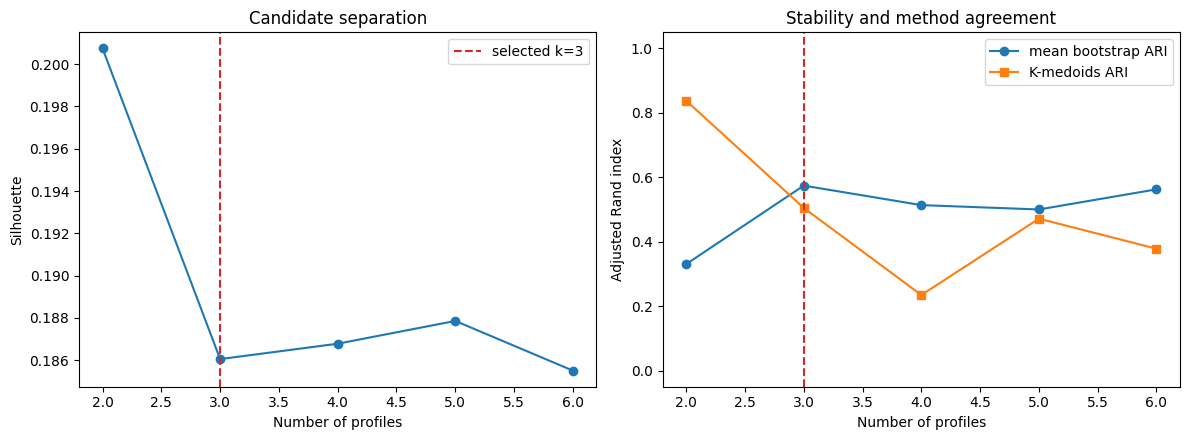

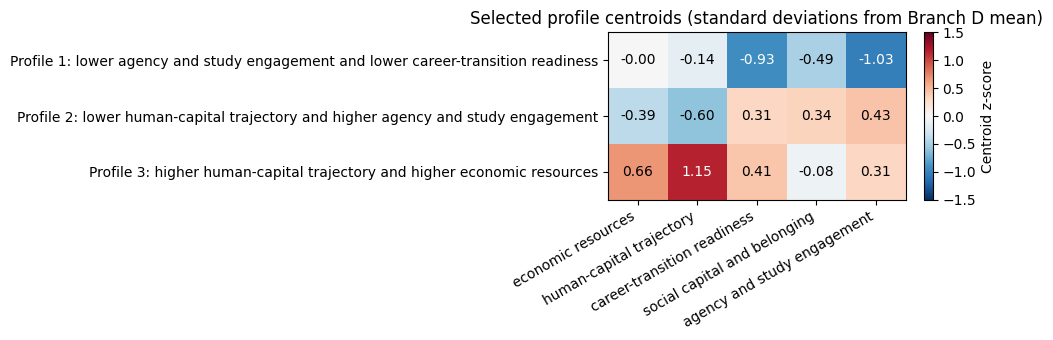

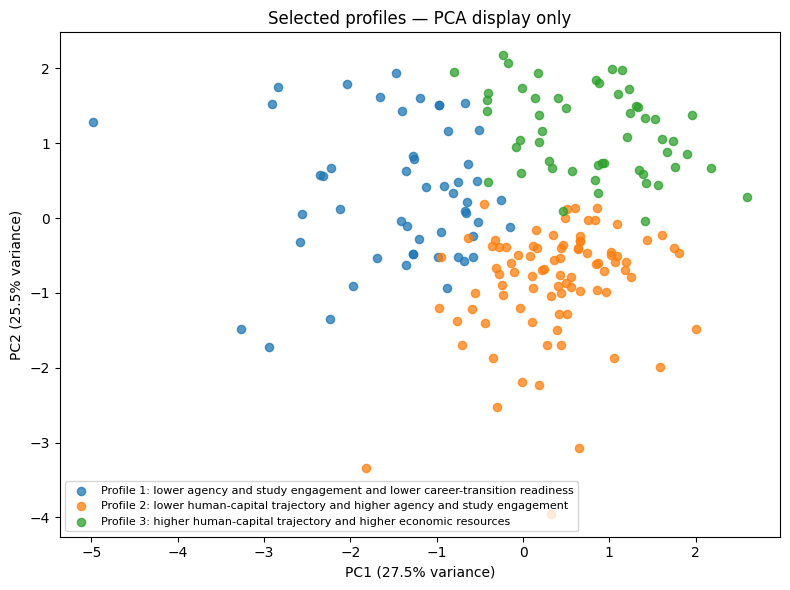

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(candidate_metrics["k"], candidate_metrics["silhouette"], marker="o")
axes[0].axvline(selected_k, color="tab:red", linestyle="--", label=f"selected k={selected_k}")
axes[0].set(title="Candidate separation", xlabel="Number of profiles", ylabel="Silhouette")
axes[0].legend()

axes[1].plot(candidate_metrics["k"], candidate_metrics["bootstrap_ari_mean"], marker="o", label="mean bootstrap ARI")
axes[1].plot(candidate_metrics["k"], candidate_metrics["kmedoids_ari"], marker="s", label="K-medoids ARI")
axes[1].axvline(selected_k, color="tab:red", linestyle="--")
axes[1].set(title="Stability and method agreement", xlabel="Number of profiles", ylabel="Adjusted Rand index", ylim=(-0.05, 1.05))
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / "candidate_solution_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, max(3.5, selected_k * 0.8)))
heat = ax.imshow(profile_z.to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(DIMENSIONS)), [FRIENDLY[d] for d in DIMENSIONS], rotation=30, ha="right")
ax.set_yticks(range(selected_k), [profile_names[i] for i in profile_z.index])
for i in range(selected_k):
    for j in range(len(DIMENSIONS)):
        value = profile_z.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if abs(value) > 0.75 else "black")
ax.set_title("Selected profile centroids (standard deviations from Branch D mean)")
fig.colorbar(heat, ax=ax, label="Centroid z-score")
fig.tight_layout()
fig.savefig(OUT / "selected_profile_centroid_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_plot = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 6))
for pid in sorted(np.unique(profile_id)):
    mask = profile_id == pid
    ax.scatter(X_plot[mask, 0], X_plot[mask, 1], alpha=0.75, s=35, label=profile_names[int(pid)])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.set_title("Selected profiles — PCA display only")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(OUT / "selected_profile_pca_display.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Save reproducible results

The assignments file contains respondent-level profile membership and uncertainty diagnostics. The saved scaler and K-means model allow the exact solution to be reproduced, subject to the same five score definitions.

In [10]:
candidate_metrics.to_csv(OUT / "branch_d_level2_candidate_metrics.csv", index=False)
bootstrap_stability.to_csv(OUT / "branch_d_level2_bootstrap_stability.csv", index=False)
standardization_audit.to_csv(OUT / "branch_d_level2_standardization_audit.csv", index=False)
assignments.to_csv(OUT / "branch_d_integrated_profile_assignments.csv", index=False)
profile_sizes.to_csv(OUT / "branch_d_integrated_profile_sizes.csv", index=False)
profile_means.to_csv(OUT / "branch_d_integrated_profile_means_0_100.csv")
profile_medians.to_csv(OUT / "branch_d_integrated_profile_medians_0_100.csv")
profile_sds.to_csv(OUT / "branch_d_integrated_profile_sds_0_100.csv")
profile_z_export.to_csv(OUT / "branch_d_integrated_profile_centroids_z.csv")
distinguishing.to_csv(OUT / "branch_d_integrated_profile_distinguishing_dimensions.csv", index=False)
profile_composition.to_csv(OUT / "branch_d_integrated_profile_composition.csv", index=False)
algorithm_comparison.to_csv(OUT / "branch_d_level2_algorithm_comparison.csv", index=False)
leave_one_out.to_csv(OUT / "branch_d_level2_leave_one_dimension_out.csv", index=False)
quality_checks.to_csv(OUT / "branch_d_level2_quality_checks.csv", index=False)
joblib.dump(scaler, OUT / "branch_d_level2_standard_scaler.joblib")
joblib.dump(final_model, OUT / "branch_d_level2_kmeans.joblib")

summary = {
    "cohort": {
        "branch": "D",
        "routing_basis": "validated final active branch inherited from Level 1",
        "records": int(len(assignments)),
        "dimensions": DIMENSIONS,
        "complete_five_dimension_rows": int(scores[DIMENSIONS].notna().all(axis=1).sum()),
    },
    "method": {
        "primary": "K-means on five equally z-standardized Level 1 dimension scores",
        "substantive_candidate_k": [3, 4, 5],
        "boundary_diagnostic_k": [2, 6],
        "bootstrap_repetitions": BOOTSTRAP_REPETITIONS,
        "minimum_profile_size": MIN_PROFILE_SIZE,
        "selection_rule": selection_reason,
    },
    "selected_solution": {
        "k": selected_k,
        "silhouette": float(selected_metrics["silhouette"]),
        "calinski_harabasz": float(selected_metrics["calinski_harabasz"]),
        "davies_bouldin": float(selected_metrics["davies_bouldin"]),
        "bootstrap_ari_mean": float(selected_metrics["bootstrap_ari_mean"]),
        "bootstrap_ari_p10": float(selected_metrics["bootstrap_ari_p10"]),
        "kmedoids_ari": float(algorithm_comparison.iloc[0]["adjusted_rand_index"]),
        "ward_ari": float(algorithm_comparison.iloc[1]["adjusted_rand_index"]),
        "profile_names": {str(k): v for k, v in profile_names.items()},
        "profile_sizes": {str(int(row.profile_id)): int(row.records) for row in profile_sizes.itertuples()},
        "low_confidence_memberships": int(assignments["low_confidence_membership"].sum()),
    },
    "quality": {
        "checks_passed": int(quality_checks["passed"].sum()),
        "checks_total": int(len(quality_checks)),
        "status": interpretation_status,
        "agency_score_caution": "Level 1 agency alpha was approximately 0.551 and remains a substantive interpretation caveat.",
        "crosswalk_caution": "Study-to-career alignment relies on the documented Level 1 crosswalk and requires expert review.",
    },
}

with open(OUT / "branch_d_integrated_profiles_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

print(json.dumps(summary, indent=2))
print("\nSaved files:")
for path in sorted(OUT.iterdir()):
    print(" -", path.name)

{
  "cohort": {
    "branch": "D",
    "routing_basis": "validated final active branch inherited from Level 1",
    "records": 191,
    "dimensions": [
      "economic_resources",
      "human_capital_trajectory",
      "career_transition_readiness",
      "social_capital_belonging",
      "agency_study_engagement"
    ],
    "complete_five_dimension_rows": 191
  },
  "method": {
    "primary": "K-means on five equally z-standardized Level 1 dimension scores",
    "substantive_candidate_k": [
      3,
      4,
      5
    ],
    "boundary_diagnostic_k": [
      2,
      6
    ],
    "bootstrap_repetitions": 100,
    "minimum_profile_size": 15,
    "selection_rule": "Selected k=3 from the eligible 3\u20135 profile candidates using the lowest equal-weight mean rank across separation, compactness, bootstrap stability, and K-medoids agreement."
  },
  "selected_solution": {
    "k": 3,
    "silhouette": 0.18605192224602995,
    "calinski_harabasz": 42.63151173101712,
    "davies_bouldin": 

## Interpretation guardrails

- These are **integrated transition profiles**, not diagnoses, fixed identities, or causal types.
- Profile labels summarize the largest centroid deviations; the complete five-dimension centroid must accompany every written interpretation.
- Small score differences should not be overstated, especially where individual silhouette values are low.
- The agency score's modest internal-consistency diagnostic and the study-to-career crosswalk remain explicit limitations inherited from Level 1.
- Before publication, compare the profiles with theoretically relevant external variables and assess whether they remain meaningful to subject-matter experts.